# **Étude de FrozenLake avec Programmation Dynamique**
## **Value Iteration & Policy Iteration**


# 1. Setup et Environnement

In [46]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

# Configuration globale

np.random.seed(42)
GAMMA = 0.99             # Facteur d'actualisation
THETA = 1e-8             # Seuil de convergence
N_EPISODES_EVAL = 1000   # Nombre d'episodes pour evaluation

In [47]:
def make_env(map_name="4x4", is_slippery=True):
# Création d'un environnement FrozenLake

    env = gym.make('FrozenLake-v1', map_name=map_name, is_slippery=is_slippery, render_mode='rgb_array')
    return env

# Initialisation de l'environnement

env = make_env(map_name="4x4", is_slippery=True)
print(f"Environnement : FrozenLake-v1")

Environnement : FrozenLake-v1


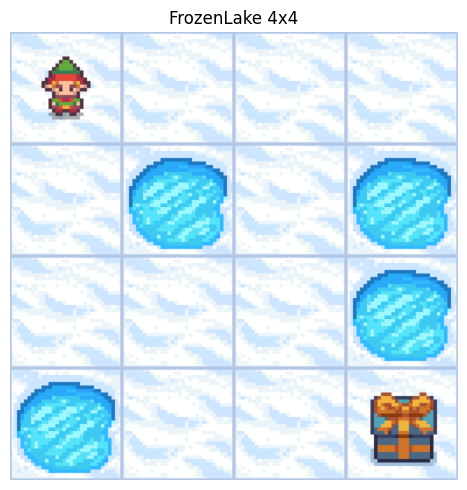

In [48]:
# On affiche l'environnement :
plt.figure(figsize=(5, 5))
state, info = env.reset()
plt.imshow(env.render())
plt.axis('off')
plt.title("FrozenLake 4x4")
plt.tight_layout()
plt.show()

In [49]:
# Descriptions de l'environnement:
n_states = env.observation_space.n
n_actions = env.action_space.n

print(f"Nombre d'états : {n_states}")
print(f"Nombre d'actions : {n_actions}")
print(f"\nActions disponibles :")
print("  0: LEFT ←")
print("  1: DOWN ↓")
print("  2: RIGHT →")
print("  3: UP ↑")

Nombre d'états : 16
Nombre d'actions : 4

Actions disponibles :
  0: LEFT ←
  1: DOWN ↓
  2: RIGHT →
  3: UP ↑


## 2. Outils de Visualisation

In [50]:
def plot_grid(env, title="FrozenLake Grid"):

    plt.figure(figsize=(5, 5))
    plt.imshow(env.render())
    plt.axis('off')
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [51]:
def plot_value_policy(V, policy, env, title="Value Function & Optimal Policy"):
    """
    cette fonction visualise la fonction de valeur avec heatmap et la politique optimale avec flèches

    les args seront:
        V: vecteur de valeurs d'état
        policy: politique optimale (vecteur d'actions)
        env: environnement Gymnasium
        title: titre du graphique
    """
    n_states = env.observation_space.n
    grid_size = int(np.sqrt(n_states))

    V_grid = V.reshape(grid_size, grid_size)

    fig, ax = plt.subplots(figsize=(8, 7))

    # Heatmap
    im = ax.imshow(V_grid, cmap='YlOrRd', interpolation='nearest')
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('State Value', rotation=270, labelpad=20)

    # Afficher les valeurs numeriques dans chaque case
    for i in range(grid_size):
        for j in range(grid_size):
            state = i * grid_size + j
            text = ax.text(j, i, f'{V[state]:.2f}',
                          ha="center", va="center", color="black", fontsize=10, weight='bold')

    # Fleches pour la politique
    arrow_mapping = {
        0: (-0.3, 0),     # LEFT
        1: (0, 0.3),      # DOWN
        2: (0.3, 0),      # RIGHT
        3: (0, -0.3)      # UP
    }

    for i in range(grid_size):
        for j in range(grid_size):
            state = i * grid_size + j
            action = policy[state]
            dx, dy = arrow_mapping[action]

            # Dessiner la fleche
            arrow = FancyArrowPatch((j, i), (j + dx, i + dy),
                                   arrowstyle='->', mutation_scale=20,
                                   color='blue', linewidth=2, alpha=0.7)
            ax.add_patch(arrow)

    # Configuration des axes
    ax.set_xticks(np.arange(grid_size))
    ax.set_yticks(np.arange(grid_size))
    ax.set_xticklabels(np.arange(grid_size))
    ax.set_yticklabels(np.arange(grid_size))
    ax.set_title(title, fontsize=14, weight='bold', pad=20)
    ax.grid(False)

    plt.tight_layout()
    plt.show()

 ## 3. Value Iteration


 ### Équation de Bellman optimale

 $$V^*(s) = \max_a \sum_{s'} P(s'|s,a) \left[ R(s,a,s') + \gamma V^*(s') \right]$$


In [52]:
def value_iteration(env, gamma=GAMMA, theta=THETA, max_iterations=1000):
    """
    On implemente dans ce cell l'algorithme Value Iteration

    les args:
        env: environnement Gymnasium
        gamma: facteur d'actualisation
        theta: seuil de convergence
        max_iterations: nombre max d'iterations

    Returns:
        V: fonction de valeur optimale
        policy: politique optimale
        n_iterations: nombre d'itérations effectuees
    """
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    # Initialisation de V à zéro
    V = np.zeros(n_states)

    for iteration in range(max_iterations):
        delta = 0
        V_old = V.copy()

        # Mise à jour de V pour chaque état
        for s in range(n_states):
            # Calcule de la valeur pour chaque action
            action_values = np.zeros(n_actions)
            for a in range(n_actions):
                # Somme sur tous les etats suivants possibles
                for prob, next_state, reward, done in env.unwrapped.P[s][a]:
                    action_values[a] += prob * (reward + gamma * V_old[next_state])

            # Prendre le maximum
            V[s] = np.max(action_values)
            delta = max(delta, abs(V[s] - V_old[s]))

        # Verifier la convergence
        if delta < theta:
            print(f" Convergence atteinte à l'itération {iteration + 1}")
            break

    # Extraire la politique optimale
    policy = np.zeros(n_states, dtype=int)
    for s in range(n_states):
        action_values = np.zeros(n_actions)
        for a in range(n_actions):
            for prob, next_state, reward, done in env.unwrapped.P[s][a]:
                action_values[a] += prob * (reward + gamma * V[next_state])
        policy[s] = np.argmax(action_values)

    return V, policy, iteration + 1

In [53]:
# Application de Value Iteration sur FrozenLake 4x4 stochastique
print(" Value Iteration sur FrozenLake 4x4 (Stochastic) :")
V_vi, policy_vi, n_iter_vi = value_iteration(env, gamma=GAMMA, theta=THETA)

print(f"\nNombre d'iterations : {n_iter_vi}")
print(f"Valeur de l'etat initial (S) : {V_vi[0]:.4f}")

 Value Iteration sur FrozenLake 4x4 (Stochastic) :
 Convergence atteinte à l'itération 438

Nombre d'iterations : 438
Valeur de l'etat initial (S) : 0.5420


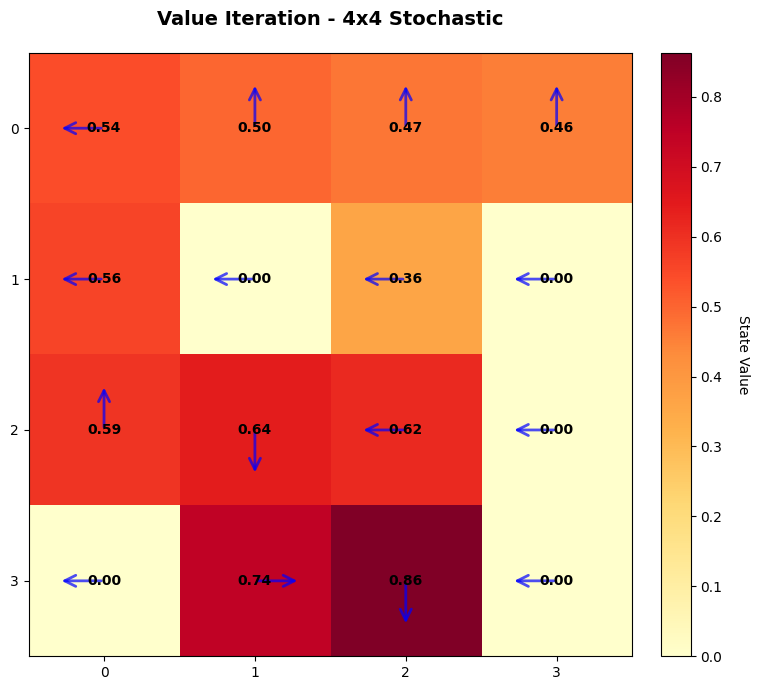

In [54]:
plot_value_policy(V_vi, policy_vi, env, title="Value Iteration - 4x4 Stochastic")

 ## 4. Policy Iteration

 ### Policy Evaluation

 $$V^\pi(s) = \sum_{s'} P(s'|s,\pi(s)) \left[ R(s,\pi(s),s') + \gamma V^\pi(s') \right]$$

 ### Policy Improvement

 $$\pi'(s) = \arg\max_a \sum_{s'} P(s'|s,a) \left[ R(s,a,s') + \gamma V^\pi(s') \right]$$


In [55]:
def policy_evaluation(policy, env, gamma=GAMMA, theta=THETA, max_iterations=1000):
    """
    on evalue une politique donnee

    args:
        policy: politique à évaluer
        env: environnement
        gamma: facteur d'actualisation
        theta: seuil de convergence
        max_iterations: nombre max d'itérations

    Returns:
        V: fonction de valeur de la politique
    """
    n_states = env.observation_space.n
    V = np.zeros(n_states)

    for _ in range(max_iterations):
        delta = 0
        V_old = V.copy()

        for s in range(n_states):
            # Action déterminée par la politique
            a = policy[s]
            v = 0

            # Calcule de la valeur selon la politique
            for prob, next_state, reward, done in env.unwrapped.P[s][a]:
                v += prob * (reward + gamma * V_old[next_state])

            V[s] = v
            delta = max(delta, abs(V[s] - V_old[s]))

        if delta < theta:
            break

    return V

def policy_improvement(V, env, gamma=GAMMA):
    """
    Ameliore la politique en se basant sur la fonction de valeur

    Args:
        V: fonction de valeur actuelle
        env: environnement
        gamma: facteur d'actualisation

    Returns:
        policy: politique améliorée
    """
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    policy = np.zeros(n_states, dtype=int)

    for s in range(n_states):
        action_values = np.zeros(n_actions)

        for a in range(n_actions):
            for prob, next_state, reward, done in env.unwrapped.P[s][a]:
                action_values[a] += prob * (reward + gamma * V[next_state])

        policy[s] = np.argmax(action_values)

    return policy

In [56]:
def policy_iteration(env, gamma=GAMMA, theta=THETA, max_iterations=1000):
    """
    Implemente l'algorithme Policy Iteration

    Args:
        env: environnement Gymnasium
        gamma: facteur d'actualisation
        theta: seuil de convergence
        max_iterations: nombre max d'itérations

    Returns:
        V: fonction de valeur optimale
        policy: politique optimale
        n_iterations: nombre d'itérations effectuées
    """
    n_states = env.observation_space.n

    # Initialisation avec une politique aléatoire
    policy = np.random.randint(0, env.action_space.n, size=n_states)

    for iteration in range(max_iterations):
        # Policy Evaluation
        V = policy_evaluation(policy, env, gamma, theta)

        # Policy Improvement
        new_policy = policy_improvement(V, env, gamma)

        # Vérifier si la politique a convergé
        if np.array_equal(policy, new_policy):
            print(f" Convergence atteinte à l'itération {iteration + 1}")
            return V, new_policy, iteration + 1

        policy = new_policy

    return V, policy, max_iterations

In [57]:
# Application de Policy Iteration sur FrozenLake 4x4 stochastique
print(" Policy Iteration sur FrozenLake 4x4 (Stochastic) ")
V_pi, policy_pi, n_iter_pi = policy_iteration(env, gamma=GAMMA, theta=THETA)

print(f"\nNombre d'itérations : {n_iter_pi}")
print(f"Valeur de l'état initial (S) : {V_pi[0]:.4f}")

 Policy Iteration sur FrozenLake 4x4 (Stochastic) 
 Convergence atteinte à l'itération 4

Nombre d'itérations : 4
Valeur de l'état initial (S) : 0.5420


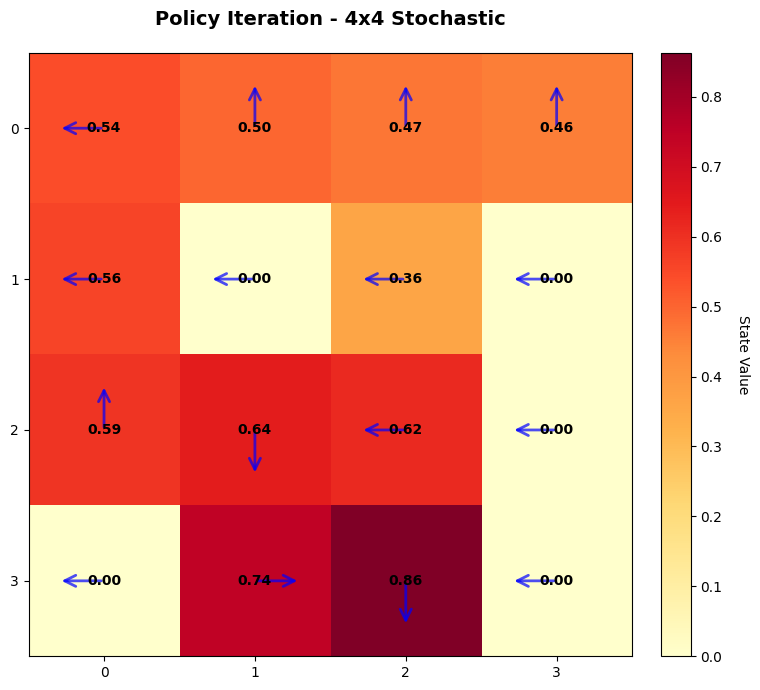

In [58]:
plot_value_policy(V_pi, policy_pi, env, title="Policy Iteration - 4x4 Stochastic")

 ## 5. Comparaisons


 ### 5.1 Value Iteration vs Policy Iteration

In [59]:
# Comparaison VI vs PI
print("  Comparaison VI vs PI ")
print(f"Value Iteration    - Itérations : {n_iter_vi}, V(S) : {V_vi[0]:.6f}")
print(f"Policy Iteration   - Itérations : {n_iter_pi}, V(S) : {V_pi[0]:.6f}")
print(f"Différence |V_VI - V_PI| : {np.max(np.abs(V_vi - V_pi)):.10f}")
print(f"Politiques identiques : {np.array_equal(policy_vi, policy_pi)}")

  Comparaison VI vs PI 
Value Iteration    - Itérations : 438, V(S) : 0.542026
Policy Iteration   - Itérations : 4, V(S) : 0.542026
Différence |V_VI - V_PI| : 0.0000000013
Politiques identiques : True


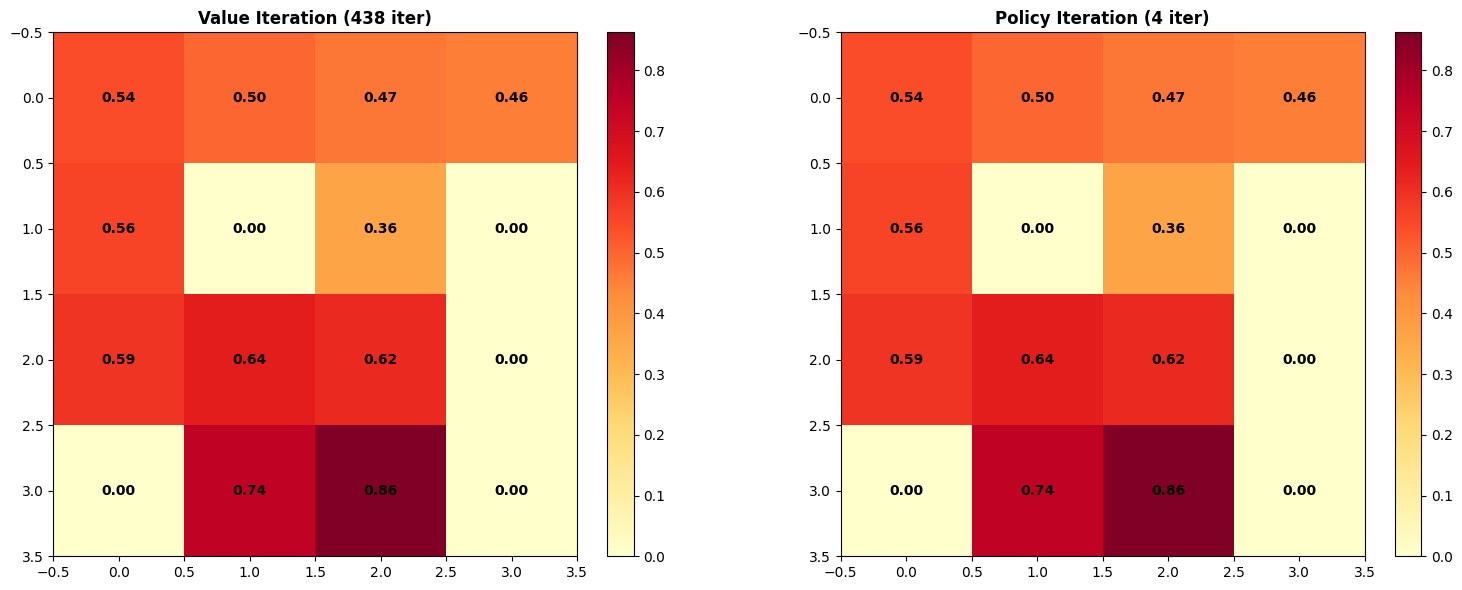

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Value Iteration
grid_size = int(np.sqrt(len(V_vi)))
V_grid_vi = V_vi.reshape(grid_size, grid_size)
im1 = axes[0].imshow(V_grid_vi, cmap='YlOrRd', interpolation='nearest')
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

for i in range(grid_size):
    for j in range(grid_size):
        state = i * grid_size + j
        axes[0].text(j, i, f'{V_vi[state]:.2f}', ha="center", va="center",
                    color="black", fontsize=10, weight='bold')

axes[0].set_title(f"Value Iteration ({n_iter_vi} iter)", fontsize=12, weight='bold')
axes[0].grid(False)

# Policy Iteration
V_grid_pi = V_pi.reshape(grid_size, grid_size)
im2 = axes[1].imshow(V_grid_pi, cmap='YlOrRd', interpolation='nearest')
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

for i in range(grid_size):
    for j in range(grid_size):
        state = i * grid_size + j
        axes[1].text(j, i, f'{V_pi[state]:.2f}', ha="center", va="center",
                    color="black", fontsize=10, weight='bold')

axes[1].set_title(f"Policy Iteration ({n_iter_pi} iter)", fontsize=12, weight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

### 5.2 Stochastic vs Deterministic

In [61]:
# Environnement déterministe
env_det = make_env(map_name="4x4", is_slippery=False)

print(" FrozenLake 4x4 Deterministic ")
V_det, policy_det, n_iter_det = value_iteration(env_det, gamma=GAMMA, theta=THETA)
print(f"Nombre d'itérations : {n_iter_det}")
print(f"Valeur de l'état initial : {V_det[0]:.4f}")

 FrozenLake 4x4 Deterministic 
 Convergence atteinte à l'itération 7
Nombre d'itérations : 7
Valeur de l'état initial : 0.9510


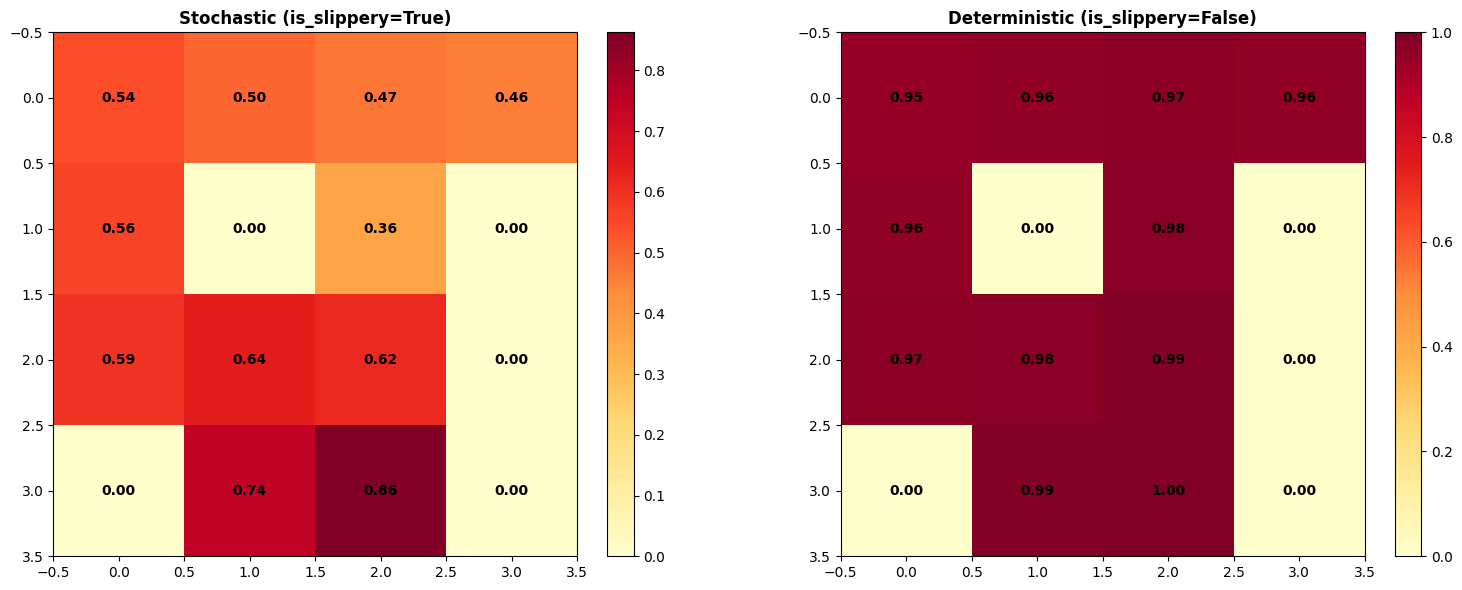


Différence de valeur initiale : 0.4090


In [62]:
# Visualisation côte à côte
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Stochastic
V_grid_stoch = V_vi.reshape(4, 4)
im1 = axes[0].imshow(V_grid_stoch, cmap='YlOrRd', interpolation='nearest')
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

for i in range(4):
    for j in range(4):
        state = i * 4 + j
        axes[0].text(j, i, f'{V_vi[state]:.2f}', ha="center", va="center",
                    color="black", fontsize=10, weight='bold')

axes[0].set_title("Stochastic (is_slippery=True)", fontsize=12, weight='bold')
axes[0].grid(False)

# Deterministic
V_grid_det = V_det.reshape(4, 4)
im2 = axes[1].imshow(V_grid_det, cmap='YlOrRd', interpolation='nearest')
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

for i in range(4):
    for j in range(4):
        state = i * 4 + j
        axes[1].text(j, i, f'{V_det[state]:.2f}', ha="center", va="center",
                    color="black", fontsize=10, weight='bold')

axes[1].set_title("Deterministic (is_slippery=False)", fontsize=12, weight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

print(f"\nDifférence de valeur initiale : {V_det[0] - V_vi[0]:.4f}")

### 5.3 Grille 4x4 vs 8x8

In [63]:
# Environnement 8x8
env_8x8 = make_env(map_name="8x8", is_slippery=True)

print(" FrozenLake 8x8 Stochastic ")
V_8x8, policy_8x8, n_iter_8x8 = value_iteration(env_8x8, gamma=GAMMA, theta=THETA)
print(f"Nombre d'itérations : {n_iter_8x8}")
print(f"Valeur de l'état initial : {V_8x8[0]:.4f}")

 FrozenLake 8x8 Stochastic 
 Convergence atteinte à l'itération 516
Nombre d'itérations : 516
Valeur de l'état initial : 0.4146


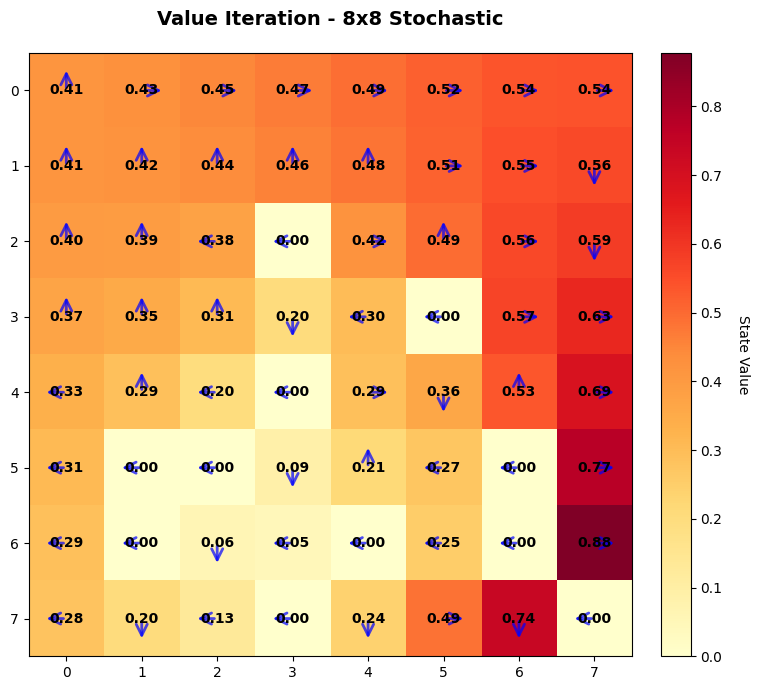

In [64]:
# Visualisation 8x8
plot_value_policy(V_8x8, policy_8x8, env_8x8, title="Value Iteration - 8x8 Stochastic")

In [65]:
# Comparaison 4x4 vs 8x8
print(" Comparaison 4x4 vs 8x8 ")
print(f"4x4 - Itérations : {n_iter_vi}, V(S) : {V_vi[0]:.6f}")
print(f"8x8 - Itérations : {n_iter_8x8}, V(S) : {V_8x8[0]:.6f}")

 Comparaison 4x4 vs 8x8 
4x4 - Itérations : 438, V(S) : 0.542026
8x8 - Itérations : 516, V(S) : 0.414640


## 6. Evaluation Empirique

In [66]:
def evaluate_policy(env, policy, n_episodes=N_EPISODES_EVAL, seed=42):
    """
    Évalue une politique sur n épisodes

    Args:
        env: environnement
        policy: politique à évaluer
        n_episodes: nombre d'épisodes
        seed: graine aléatoire

    Returns:
        success_rate: taux de réussite
        avg_reward: récompense moyenne
    """
    successes = 0
    total_reward = 0

    for episode in range(n_episodes):
        state, _ = env.reset(seed=seed + episode)
        done = False
        episode_reward = 0

        while not done:
            action = policy[state]
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            episode_reward += reward

        if reward > 0:  # Succès si récompense positive
            successes += 1
        total_reward += episode_reward

    success_rate = successes / n_episodes
    avg_reward = total_reward / n_episodes

    return success_rate, avg_reward

In [67]:
# evaluation des politiques
print(" Évaluation Empirique: \n")

# VI 4x4 Stochastic
sr_vi, ar_vi = evaluate_policy(env, policy_vi, N_EPISODES_EVAL)
print(f"Value Iteration (4x4 Stoch)    - Success Rate: {sr_vi:.2%}, Avg Reward: {ar_vi:.4f}")

# PI 4x4 Stochastic
sr_pi, ar_pi = evaluate_policy(env, policy_pi, N_EPISODES_EVAL)
print(f"Policy Iteration (4x4 Stoch)   - Success Rate: {sr_pi:.2%}, Avg Reward: {ar_pi:.4f}")

# 4x4 Deterministic
sr_det, ar_det = evaluate_policy(env_det, policy_det, N_EPISODES_EVAL)
print(f"Value Iteration (4x4 Det)      - Success Rate: {sr_det:.2%}, Avg Reward: {ar_det:.4f}")

# 8x8 Stochastic
sr_8x8, ar_8x8 = evaluate_policy(env_8x8, policy_8x8, N_EPISODES_EVAL)
print(f"Value Iteration (8x8 Stoch)    - Success Rate: {sr_8x8:.2%}, Avg Reward: {ar_8x8:.4f}")

 Évaluation Empirique: 

Value Iteration (4x4 Stoch)    - Success Rate: 75.20%, Avg Reward: 0.7520
Policy Iteration (4x4 Stoch)   - Success Rate: 75.20%, Avg Reward: 0.7520
Value Iteration (4x4 Det)      - Success Rate: 100.00%, Avg Reward: 1.0000
Value Iteration (8x8 Stoch)    - Success Rate: 62.90%, Avg Reward: 0.6290


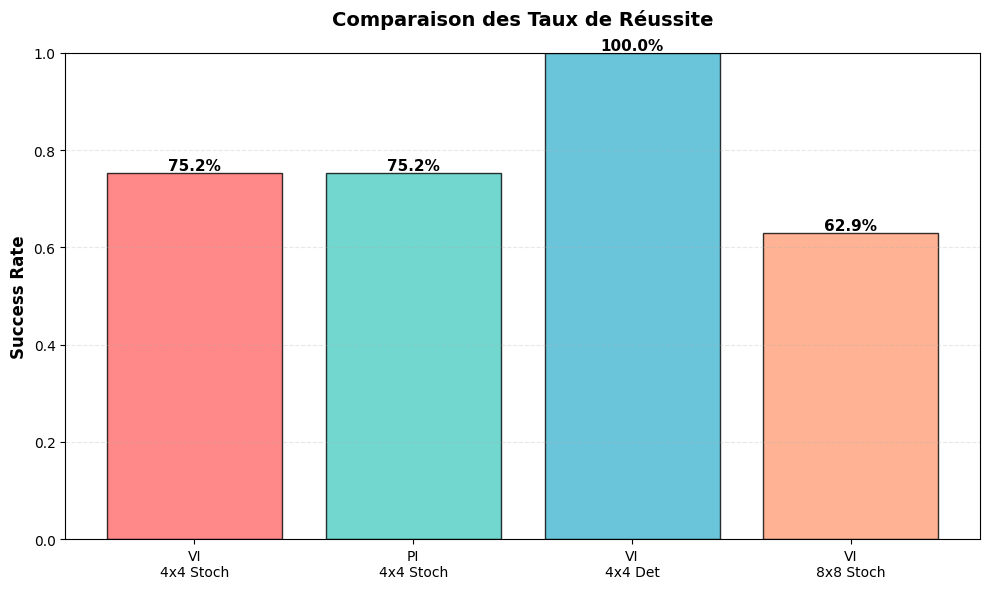

In [68]:
# Visualisation des resultats :
methods = ['VI\n4x4 Stoch', 'PI\n4x4 Stoch', 'VI\n4x4 Det', 'VI\n8x8 Stoch']
success_rates = [sr_vi, sr_pi, sr_det, sr_8x8]

plt.figure(figsize=(10, 6))
bars = plt.bar(methods, success_rates, color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A'], alpha=0.8, edgecolor='black')
plt.ylabel('Success Rate', fontsize=12, weight='bold')
plt.title('Comparaison des Taux de Réussite', fontsize=14, weight='bold', pad=20)
plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3, linestyle='--')

for bar, rate in zip(bars, success_rates):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
            f'{rate:.1%}', ha='center', va='bottom', fontsize=11, weight='bold')

plt.tight_layout()
plt.show()
